# 02 â€” Exploratory Data Analysis: MBTA Bus Reliability, 2025

**Project:** Predicting and explaining transit delays  
**Data:** MBTA *Bus Arrival Departure Times 2025* (Boston, bus mode, Janâ€“Dec 2025), scoped to 19 routes
(14 MBTA key bus routes + the 5 busiest schedule-managed routes).  
**Unit of observation:** one bus at one timepoint stop on one trip.  
**Target:** `delayed = 1` if the bus is more than **5 minutes** later than scheduled.

Questions this notebook answers:
1. How clean is the data and what did cleaning remove?
2. What does the delay distribution look like, and how imbalanced is the target?
3. *When* are buses late? (hour, weekday, peak, month, holidays)
4. *Where* are buses late? (route, direction, stop, position along the route)
5. Do delays **propagate** along a trip? Do buses **bunch**?
6. What do these findings imply for feature engineering and modelling?

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, holidays
from src.config import PROCESSED_DIR, REPORTS, FIG_DIR, DELAY_THRESHOLD_SEC

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
def save(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f'eda_{name}.png', bbox_inches='tight'); plt.show()

df = pd.read_parquet(PROCESSED_DIR / 'bus_2025_clean.parquet')
DOW = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
print(f'{len(df):,} rows | {df.memory_usage(deep=True).sum()/1e9:.2f} GB in memory')
df.head()

9,823,286 rows | 0.78 GB in memory


,service_date,route_id,direction_id,half_trip_id,stop_id,time_point_id,time_point_order,point_type,standard_type,scheduled_headway,...,scheduled_dt,actual_dt,delay_sec,delay_min,delayed,severity,hour,dow,month,is_weekend
0,2025-01-01,1,Inbound,1294,110,hhgat,1.0,Startpoint,Headway,900.0,...,2025-01-01 18:52:00,2025-01-01 18:51:52,-8.0,-0.133333,0,on_time,18,2,1,0
1,2025-01-01,1,Inbound,1294,187,masta,6.0,Midpoint,Headway,900.0,...,2025-01-01 19:18:00,2025-01-01 19:11:26,-394.0,-6.566667,0,on_time,19,2,1,0
2,2025-01-01,1,Inbound,1294,59,Wasma,7.0,Midpoint,Headway,900.0,...,2025-01-01 19:23:00,2025-01-01 19:13:25,-575.0,-9.583333,0,on_time,19,2,1,0
3,2025-01-01,1,Inbound,1294,62,Melwa,8.0,Midpoint,Headway,900.0,...,2025-01-01 19:28:00,2025-01-01 19:16:05,-715.0,-11.916667,0,on_time,19,2,1,0
4,2025-01-01,1,Inbound,1294,64,nubn,9.0,Endpoint,Headway,900.0,...,2025-01-01 19:29:00,2025-01-01 19:16:30,-750.0,-12.500000,0,on_time,19,2,1,0


## 1. Dataset overview

In [2]:
overview = pd.Series({
    'rows (stop events)': f'{len(df):,}',
    'date range': f"{df.service_date.min().date()} â†’ {df.service_date.max().date()}",
    'service days': df.service_date.nunique(),
    'routes': df.route_id.nunique(),
    'timepoint stops': df.stop_id.nunique(),
    'one-way trips (half_trip_id Ã— date)': f"{df.groupby(['service_date','half_trip_id'], observed=True).ngroups:,}",
    'headway-managed share': f"{(df.standard_type=='Headway').mean():.1%}",
})
overview.to_frame('value')

,value
rows (stop events),"9,823,286"
date range,2025-01-01 â†’ 2025-12-31
service days,365
routes,19
timepoint stops,288
one-way trips (half_trip_id Ã— date),"1,176,843"
headway-managed share,84.8%


In [3]:
df.describe(include='number').T.round(2)

,count,mean,std,min,25%,50%,75%,max
time_point_order,9823286.0,4.99,2.76,1.0,3.00,5.00,7.00,14.00
scheduled_headway,9686103.0,879.17,695.34,60.0,600.00,780.00,900.00,64860.00
headway,9305725.0,882.23,787.21,1.0,450.00,768.00,1124.00,66951.00
sched_sec,9823286.0,52723.16,20601.03,11400.0,34200.00,53040.00,69240.00,96720.00
actual_sec,9823286.0,52917.16,20638.47,11182.0,34339.00,53285.00,69457.00,98323.00
delay_sec,9823286.0,194.00,368.85,-1800.0,-1.00,135.00,343.00,7157.00
delay_min,9823286.0,3.23,6.15,-30.0,-0.02,2.25,5.72,119.28
delayed,9823286.0,0.29,0.45,0.0,0.00,0.00,1.00,1.00
hour,9823286.0,12.94,5.99,0.0,8.00,13.00,18.00,23.00
dow,9823286.0,2.80,1.92,0.0,1.00,3.00,4.00,6.00


## 2. Data quality & cleaning

Raw file audit (all 229 routes) and the cleaning funnel for the scoped routes.
Missing `actual` times are the main loss â€” they represent trips/stops that were **cancelled or not observed by AVL**.
We keep their rate per route as a reliability indicator in its own right (a cancelled trip is the worst kind of delay).

In [4]:
dq = pd.read_csv(REPORTS / 'data_quality_raw_2025.csv')
dq['month'] = dq.file.str[-11:-4]
dq['missing_actual_%'] = 100 * dq.null_actual / dq.rows_raw
display(dq[['month','rows_raw','null_actual','missing_actual_%','null_half_trip_id','exact_duplicates','key_duplicates']].round(2))
print(f"Total raw rows (all routes): {dq.rows_raw.sum():,}")
pd.read_csv(REPORTS / 'cleaning_funnel_2025.csv')

,month,rows_raw,null_actual,missing_actual_%,null_half_trip_id,exact_duplicates,key_duplicates
0,2025-01,2362132,121001,5.12,97,0,48
1,2025-02,2134786,109053,5.11,36,0,45
2,2025-03,2358661,119349,5.06,40,0,60
3,2025-04,2327708,115397,4.96,37,0,46
4,2025-05,2374824,127150,5.35,62,0,56
5,2025-06,2299212,137303,5.97,70,0,33
6,2025-07,2375950,120979,5.09,38,0,0
7,2025-08,2370600,132381,5.58,62,0,12
8,2025-09,2362666,118491,5.02,63,0,52
9,2025-10,2472273,123251,4.99,69,0,7


Total raw rows (all routes): 28,237,658


,step,rows_remaining,rows_removed,pct_of_raw
0,raw rows (scoped routes),10324982,0,100.00
1,drop exact duplicates,10324982,0,100.00
2,drop missing scheduled time,10324982,0,100.00
3,drop missing actual (cancelled / unobserved),9824195,500787,95.15
4,drop duplicate stop events (same trip/stop/sched),9824195,0,95.15
5,drop outliers (delay < -30 min or > 120 min),9823286,909,95.14


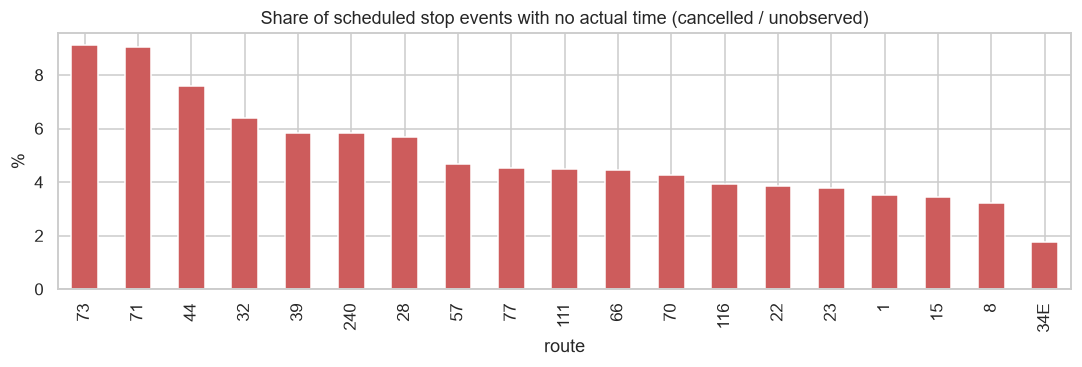

In [5]:
miss = pd.read_csv(REPORTS / 'missing_by_route_2025.csv')
m = miss.groupby('route_id').apply(lambda g: g.missing.sum()/g.rows.sum()).sort_values(ascending=False)
ax = m.mul(100).plot.bar(figsize=(10,3.5), color='indianred')
ax.set(title='Share of scheduled stop events with no actual time (cancelled / unobserved)', ylabel='%', xlabel='route')
save('missing_by_route')

## 3. Target variable: delay and the 5-minute label

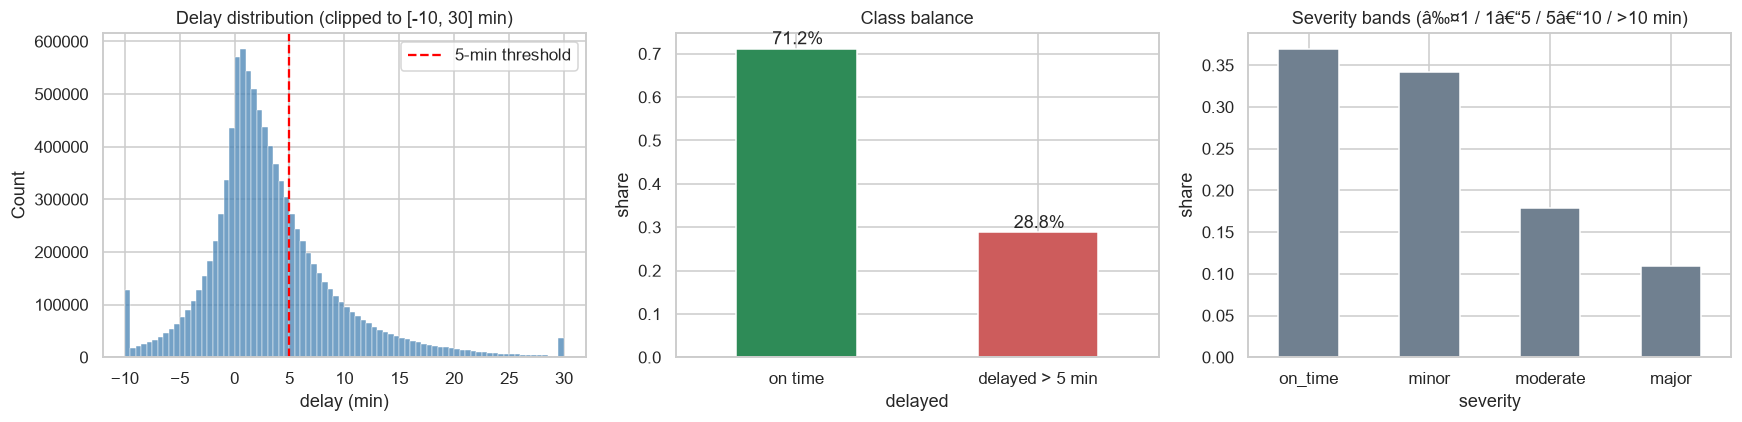

count    9823286.00
mean           3.23
std            6.15
min          -30.00
5%            -4.78
25%           -0.02
50%            2.25
75%            5.72
90%           10.47
95%           14.32
99%           23.37
max          119.28
Name: delay_min, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
d = df.delay_min.clip(-10, 30)
sns.histplot(d, bins=80, ax=axes[0], color='steelblue')
axes[0].axvline(5, color='red', ls='--', label='5-min threshold'); axes[0].legend()
axes[0].set(title='Delay distribution (clipped to [-10, 30] min)', xlabel='delay (min)')

df.delayed.value_counts(normalize=True).rename({0:'on time',1:'delayed > 5 min'}).plot.bar(ax=axes[1], color=['seagreen','indianred'])
axes[1].set(title='Class balance', ylabel='share'); axes[1].tick_params(axis='x', rotation=0)
for p in axes[1].patches: axes[1].annotate(f'{p.get_height():.1%}', (p.get_x()+0.15, p.get_height()+0.01))

df.severity.value_counts(normalize=True).reindex(['on_time','minor','moderate','major']).plot.bar(ax=axes[2], color='slategray')
axes[2].set(title='Severity bands (â‰¤1 / 1â€“5 / 5â€“10 / >10 min)', ylabel='share'); axes[2].tick_params(axis='x', rotation=0)
save('target')
print(df.delay_min.describe(percentiles=[.05,.25,.5,.75,.9,.95,.99]).round(2))

**Observations.** Delay is right-skewed: most buses run within a couple of minutes of schedule (some early),
with a long tail of large delays. Roughly 29 % of stop events are *delayed* â€” a minority class, so accuracy alone
would be misleading; we will use precision/recall/F1/ROC-AUC/PR-AUC and class weighting.

## 4. Temporal patterns â€” *when* are buses late?

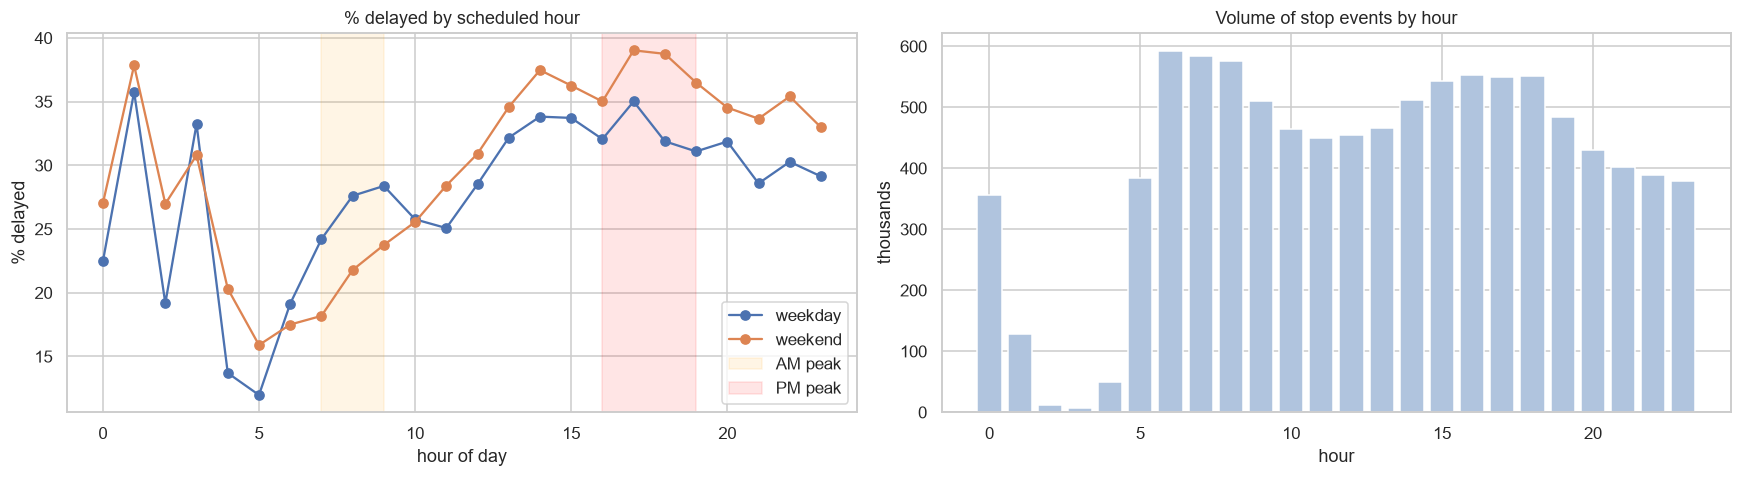

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
h = df.groupby(['hour','is_weekend']).delayed.mean().unstack().rename(columns={0:'weekday',1:'weekend'})
h.mul(100).plot(ax=axes[0], marker='o')
axes[0].axvspan(7, 9, alpha=.1, color='orange', label='AM peak'); axes[0].axvspan(16, 19, alpha=.1, color='red', label='PM peak')
axes[0].set(title='% delayed by scheduled hour', ylabel='% delayed', xlabel='hour of day'); axes[0].legend()
v = df.groupby('hour').size()
axes[1].bar(v.index, v.values/1e3, color='lightsteelblue'); axes[1].set(title='Volume of stop events by hour', ylabel='thousands', xlabel='hour')
save('by_hour')

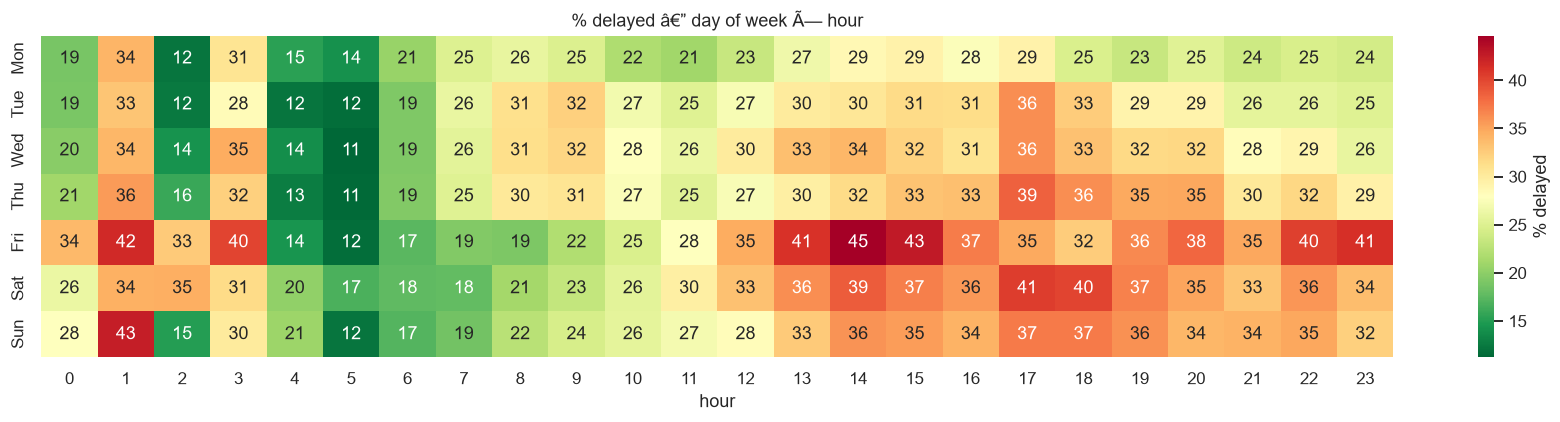

In [8]:
pv = df.pivot_table(index='dow', columns='hour', values='delayed', aggfunc='mean').mul(100)
pv.index = DOW
plt.figure(figsize=(16, 4))
sns.heatmap(pv, cmap='RdYlGn_r', annot=True, fmt='.0f', cbar_kws={'label':'% delayed'})
plt.title('% delayed â€” day of week Ã— hour'); save('heatmap_dow_hour')

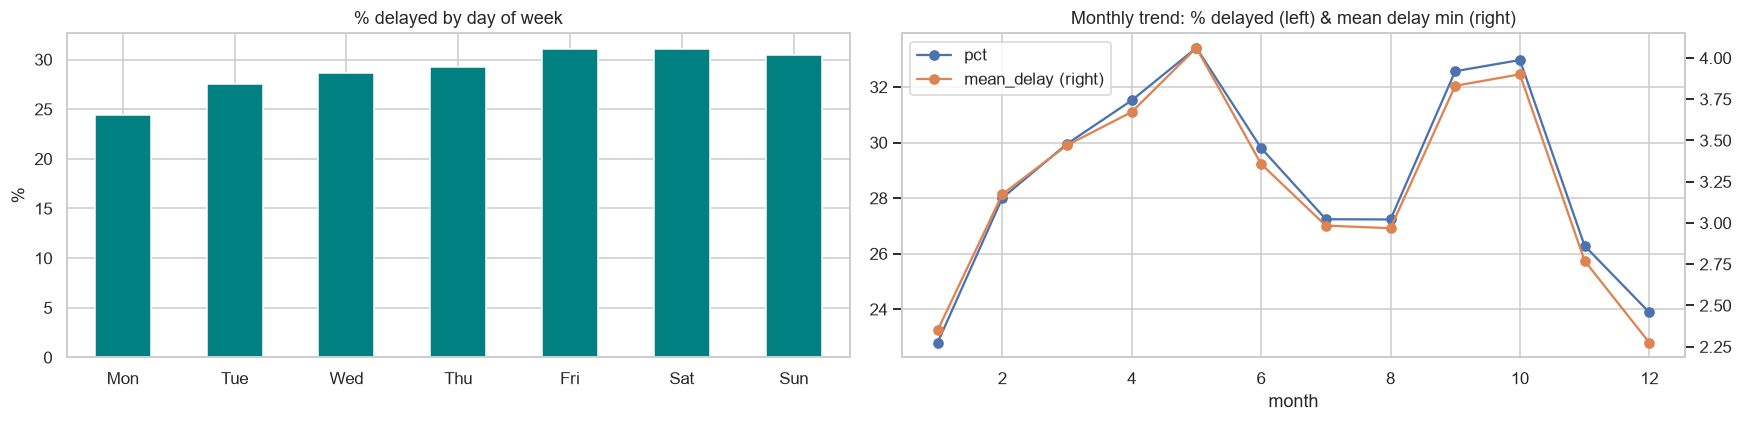

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
df.groupby('dow').delayed.mean().mul(100).set_axis(DOW).plot.bar(ax=axes[0], color='teal')
axes[0].set(title='% delayed by day of week', ylabel='%'); axes[0].tick_params(axis='x', rotation=0)
df.groupby('month').agg(pct=('delayed','mean'), mean_delay=('delay_min','mean')).assign(pct=lambda x: x.pct*100).plot(ax=axes[1], marker='o', secondary_y='mean_delay')
axes[1].set(title='Monthly trend: % delayed (left) & mean delay min (right)', xlabel='month')
save('dow_month')

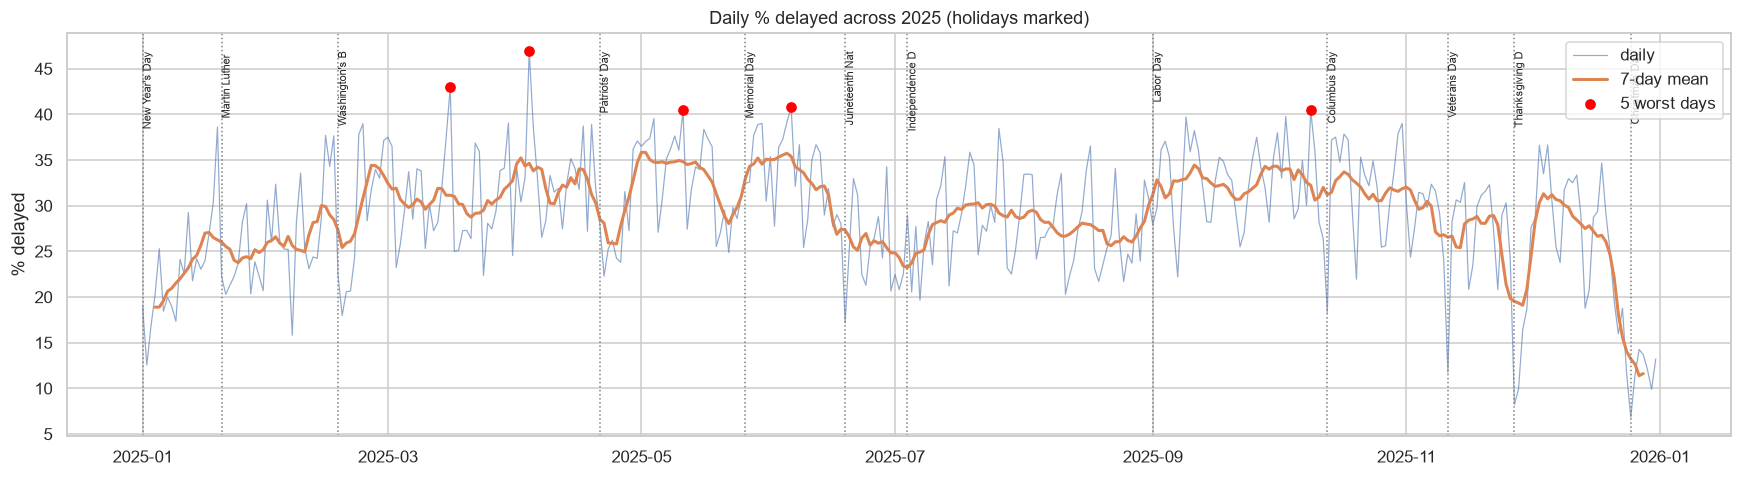

,% delayed (worst days)
service_date,
2025-04-04,46.9
2025-03-16,43.0
2025-06-06,40.8
2025-05-11,40.5
2025-10-09,40.4


% delayed
is_weekend is_holiday           
0          0                28.5
           1                19.8
1          0                30.8

In [10]:
us_ma = holidays.US(state='MA', years=2025)
daily = df.groupby('service_date').agg(pct=('delayed','mean'), n=('delayed','size'))
daily['pct'] *= 100
daily['roll7'] = daily.pct.rolling(7, center=True).mean()
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(daily.index, daily.pct, lw=.8, alpha=.6, label='daily'); ax.plot(daily.index, daily.roll7, lw=2, label='7-day mean')
for d, name in us_ma.items():
    d = pd.Timestamp(d)
    if d in daily.index: ax.axvline(d, color='grey', ls=':', lw=1); ax.text(d, daily.pct.max(), name[:14], rotation=90, fontsize=7, va='top')
worst = daily.pct.nlargest(5)
ax.scatter(worst.index, worst.values, color='red', zorder=5, label='5 worst days')
ax.set(title='Daily % delayed across 2025 (holidays marked)', ylabel='% delayed'); ax.legend()
save('daily_timeseries')
df['is_holiday'] = df.service_date.dt.date.isin(us_ma).astype('int8')
display(worst.round(1).to_frame('% delayed (worst days)'))
df.groupby(['is_weekend','is_holiday']).delayed.mean().mul(100).round(1).to_frame('% delayed')

**Observations.**
* Delay risk is lowest in the early morning (â‰ˆ12 % at 05:00), rises through the day and is highest in the
  **afternoon / PM peak (14:00â€“18:00, â‰ˆ33â€“35 % on weekdays)**. The AM peak is only moderately bad â€” traffic congestion
  accumulates over the day and late-running vehicles carry their lateness into later trips.
* Surprisingly, **weekends are worse than weekdays in the afternoon** (â‰ˆ31 % vs 28.5 % overall). A plausible explanation is
  that weekend timetables have less running-time padding while weekend traffic (shopping, events) is still heavy.
* **Public holidays are much better (â‰ˆ20 %)**, and the last two weeks of December and Thanksgiving week drop sharply.
* There is clear **seasonality**: spring (Marâ€“Jun) and Sepâ€“Oct are the worst periods, while Julyâ€“August are calmer â€”
  this lines up with the **school/university calendar** in Boston, an excellent extra feature.
* Isolated spike days (e.g. 2025-04-04, 2025-03-16) are candidates for weather or special events
  â†’ strong motivation for the **weather & events** extension.

## 5. Spatial patterns â€” *where* are buses late?

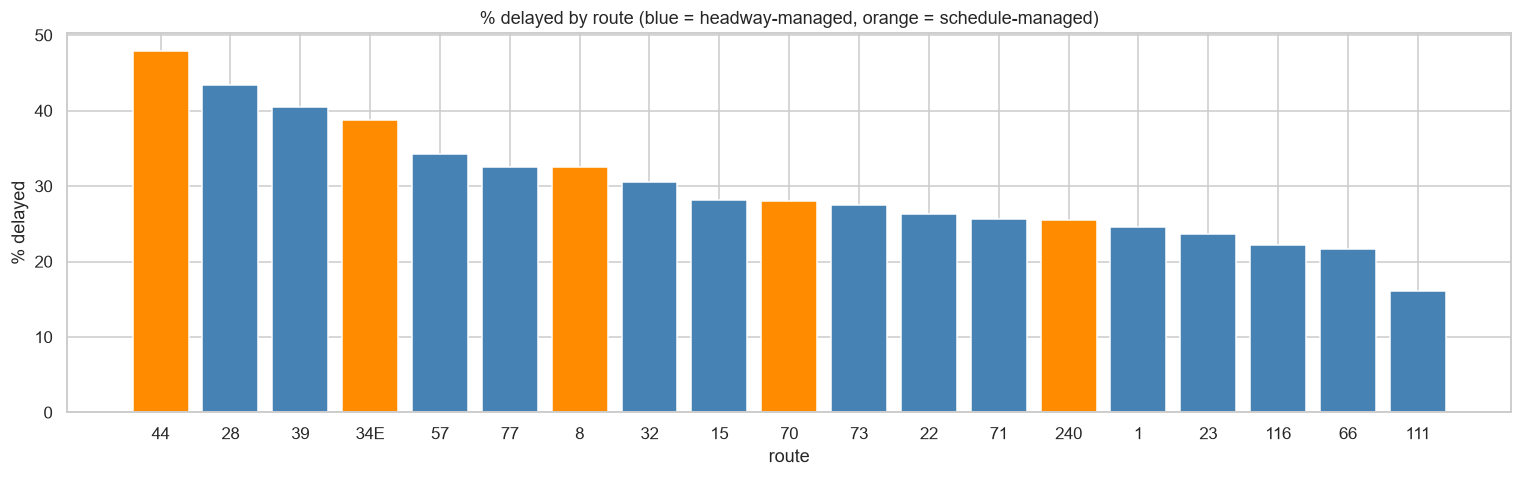

,pct,mean_delay,n,std
route_id,,,,
44,47.9,6.05,236741,Schedule
28,43.4,5.44,725246,Headway
39,40.4,5.24,626754,Headway
34E,38.7,4.72,356724,Schedule
57,34.3,4.16,567043,Headway
77,32.5,4.06,578489,Headway
8,32.5,3.38,250343,Schedule
32,30.5,3.95,538311,Headway
15,28.2,3.19,488606,Headway


In [11]:
r = (df.groupby('route_id', observed=True)
       .agg(pct=('delayed','mean'), mean_delay=('delay_min','mean'), n=('delayed','size'), std=('standard_type', lambda s: s.mode()[0]))
       .sort_values('pct', ascending=False))
fig, ax = plt.subplots(figsize=(14, 4.5))
colors = r['std'].map({'Headway':'steelblue','Schedule':'darkorange'})
ax.bar(r.index.astype(str), r.pct*100, color=colors)
ax.set(title='% delayed by route (blue = headway-managed, orange = schedule-managed)', ylabel='% delayed', xlabel='route')
save('by_route')
r.assign(pct=lambda x: (x.pct*100).round(1), mean_delay=lambda x: x.mean_delay.round(2))

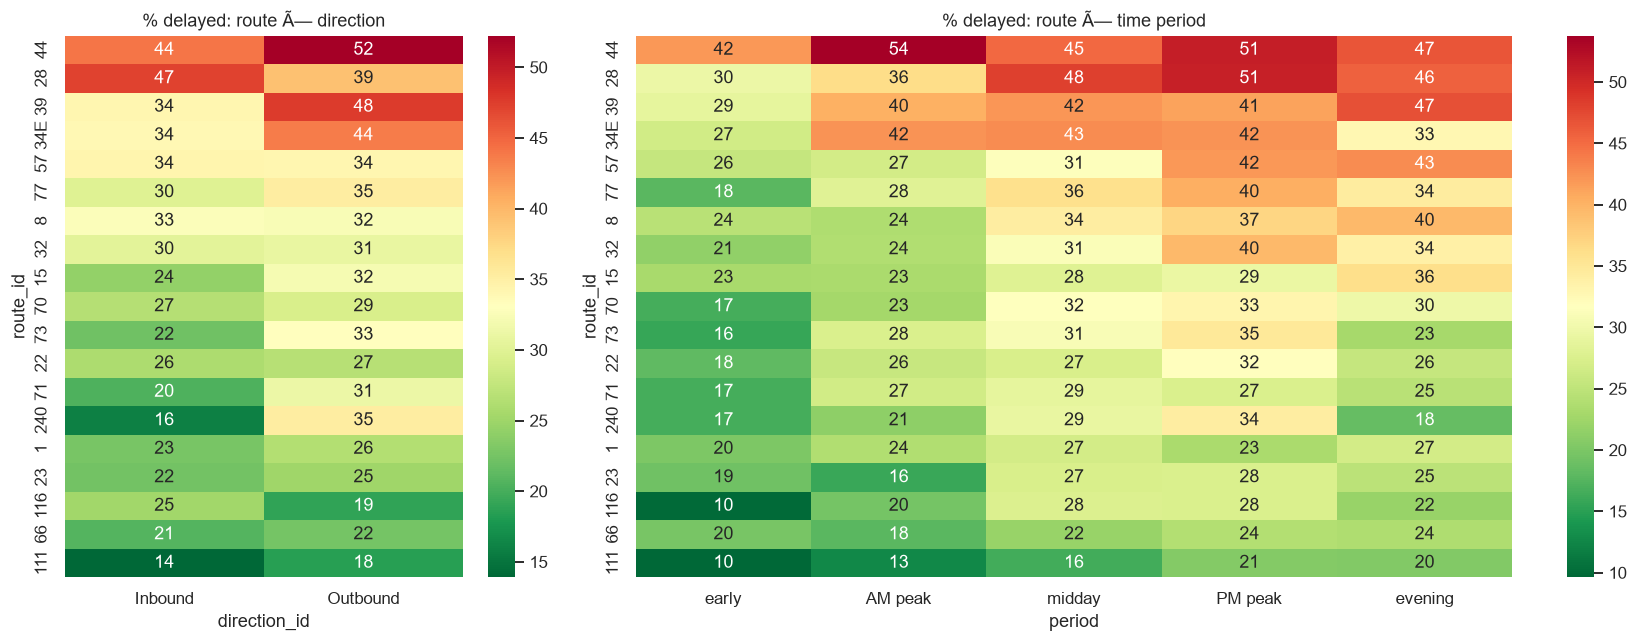

In [12]:
rd = df.pivot_table(index='route_id', columns='direction_id', values='delayed', aggfunc='mean', observed=True).mul(100)
rh = df.assign(period=pd.cut(df.hour, [-1,6,9,15,19,24], labels=['early','AM peak','midday','PM peak','evening'])) \
       .pivot_table(index='route_id', columns='period', values='delayed', aggfunc='mean', observed=True).mul(100)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios':[1,2.2]})
sns.heatmap(rd.loc[r.index], annot=True, fmt='.0f', cmap='RdYlGn_r', ax=axes[0]); axes[0].set_title('% delayed: route Ã— direction')
sns.heatmap(rh.loc[r.index], annot=True, fmt='.0f', cmap='RdYlGn_r', ax=axes[1]); axes[1].set_title('% delayed: route Ã— time period')
save('route_direction_period')

The route Ã— period heatmap already reads like the decision-tree rules we expect later, e.g.
*"route 28/39 in the PM peak â†’ very likely late"*.

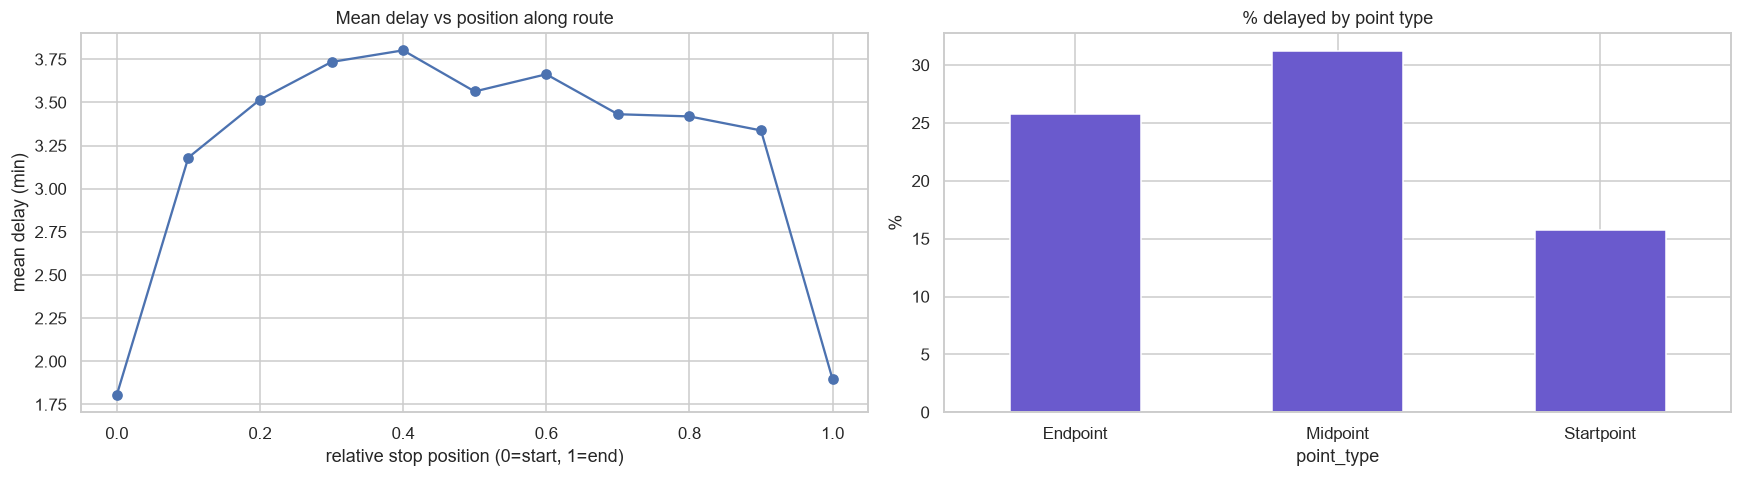

In [13]:
# Delay accumulation along the trip: timepoint order (normalised 0 = first stop, 1 = last stop)
mx = df.groupby(['route_id','direction_id'], observed=True).time_point_order.transform('max')
df['stop_pos'] = ((df.time_point_order - 1) / (mx - 1).replace(0, np.nan)).astype('float32')
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
pos = df.assign(pos_bin=(df.stop_pos*10).round()/10).groupby('pos_bin').agg(mean_delay=('delay_min','mean'), pct=('delayed','mean'))
pos.mean_delay.plot(ax=axes[0], marker='o'); axes[0].set(title='Mean delay vs position along route', xlabel='relative stop position (0=start, 1=end)', ylabel='mean delay (min)')
df.groupby('point_type', observed=True).delayed.mean().mul(100).plot.bar(ax=axes[1], color='slateblue')
axes[1].set(title='% delayed by point type', ylabel='%'); axes[1].tick_params(axis='x', rotation=0)
save('stop_position')

In [14]:
s = (df.groupby(['route_id','direction_id','stop_id','time_point_id'], observed=True)
       .agg(n=('delayed','size'), pct=('delayed','mean'), mean_delay=('delay_min','mean'))
       .query('n >= 2000').sort_values('pct', ascending=False))
print('Worst 15 route-direction-stop combinations (n â‰¥ 2000 events)')
s.head(15).assign(pct=lambda x: (x.pct*100).round(1), mean_delay=lambda x: x.mean_delay.round(2))

Worst 15 route-direction-stop combinations (n â‰¥ 2000 events)


n   pct  mean_delay
route_id direction_id stop_id time_point_id                         
44       Outbound     1354    svrhm           4129  75.8        9.46
                      1188    egles          14860  72.3        8.58
                      1346    towhm          15339  69.1        8.42
         Inbound      21148   roxbs          15985  62.6        7.62
         Outbound     40001   warwl          15088  61.6        7.57
         Inbound      396     warwl          16028  60.1        7.23
                      64000   nubn           16050  59.9        7.27
28       Inbound      64000   nubn           35091  54.4        6.96
39       Outbound     1160    shunt          32971  54.0        6.66
                      1939    jpctr          33017  53.7        6.66
28       Inbound      21148   roxbs          33761  53.6        6.73
                      396     warwl          35078  53.1        6.78
                      1737    bltal          34648  52.3        6.79
                      383     frnpk          34857  52.1        6.70
39       Outbound     31365   heath          33016  51.9        6.40

**Observations.** Delay builds quickly over the first ~40 % of a trip, then *falls* towards the terminal.
This is the signature of **schedule padding / recovery time**: planners give extra scheduled minutes to the last segment so
buses "catch up" at the endpoint. Midpoints are therefore the most delay-prone timepoints, start points the least.
Route 44 (schedule-managed) and the key routes 28 and 39 dominate the worst stop list, especially around Nubian / Roxbury.

## 6. Delay propagation & bus bunching

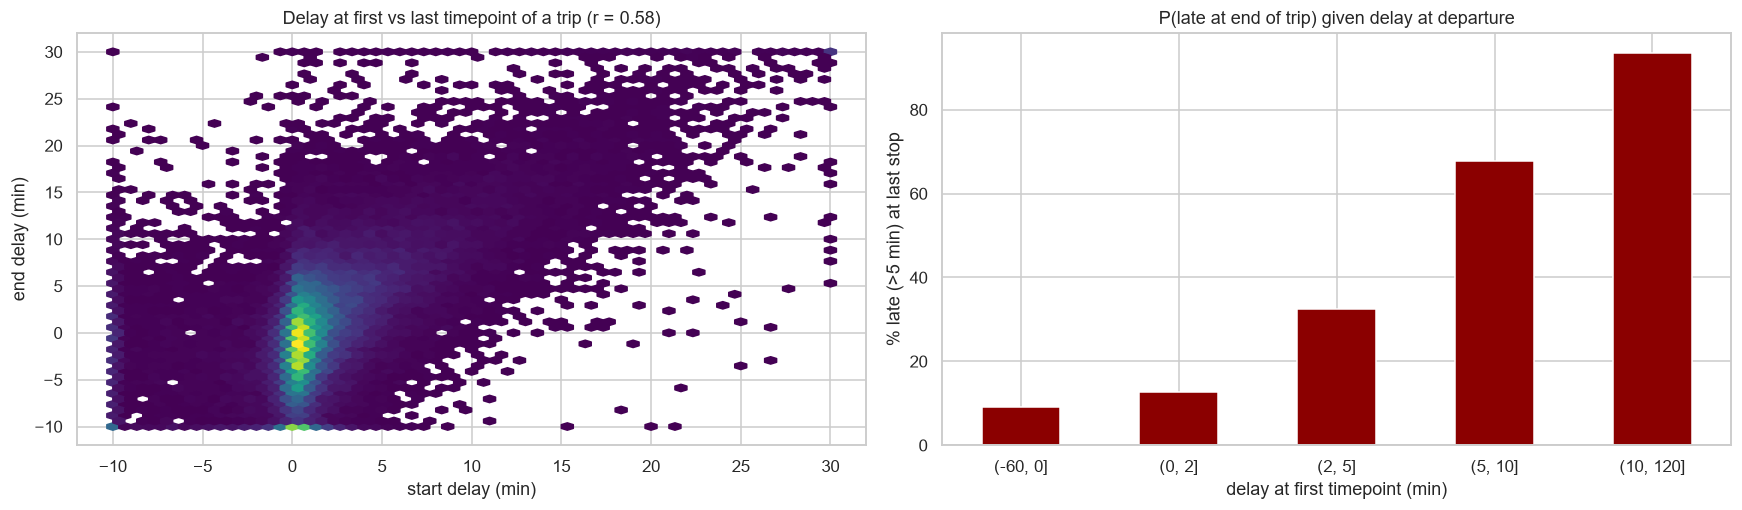

In [15]:
trip_key = ['service_date','route_id','direction_id','half_trip_id']
t = df.sort_values('time_point_order').groupby(trip_key, observed=True).agg(
        start_delay=('delay_min','first'), end_delay=('delay_min','last'), n_stops=('delay_min','size'))
t = t[t.n_stops >= 3]
corr = t[['start_delay','end_delay']].corr().iloc[0,1]
smp = t.sample(min(40000, len(t)), random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].hexbin(smp.start_delay.clip(-10,30), smp.end_delay.clip(-10,30), gridsize=60, cmap='viridis', mincnt=1)
axes[0].set(title=f'Delay at first vs last timepoint of a trip (r = {corr:.2f})', xlabel='start delay (min)', ylabel='end delay (min)')
t['start_bin'] = pd.cut(t.start_delay, [-60,0,2,5,10,120])
t.groupby('start_bin', observed=True).end_delay.apply(lambda x: (x>5).mean()*100).plot.bar(ax=axes[1], color='darkred')
axes[1].set(title='P(late at end of trip) given delay at departure', ylabel='% late (>5 min) at last stop', xlabel='delay at first timepoint (min)')
axes[1].tick_params(axis='x', rotation=0)
save('propagation')

A late departure strongly predicts a late arrival â†’ delays **propagate**. For a *forward-looking* model this
motivates two feature types: (a) **upstream delay of the same trip** (available in real-time mode) and
(b) **previous trip's delay on the same route** (lagged, leakage-safe).

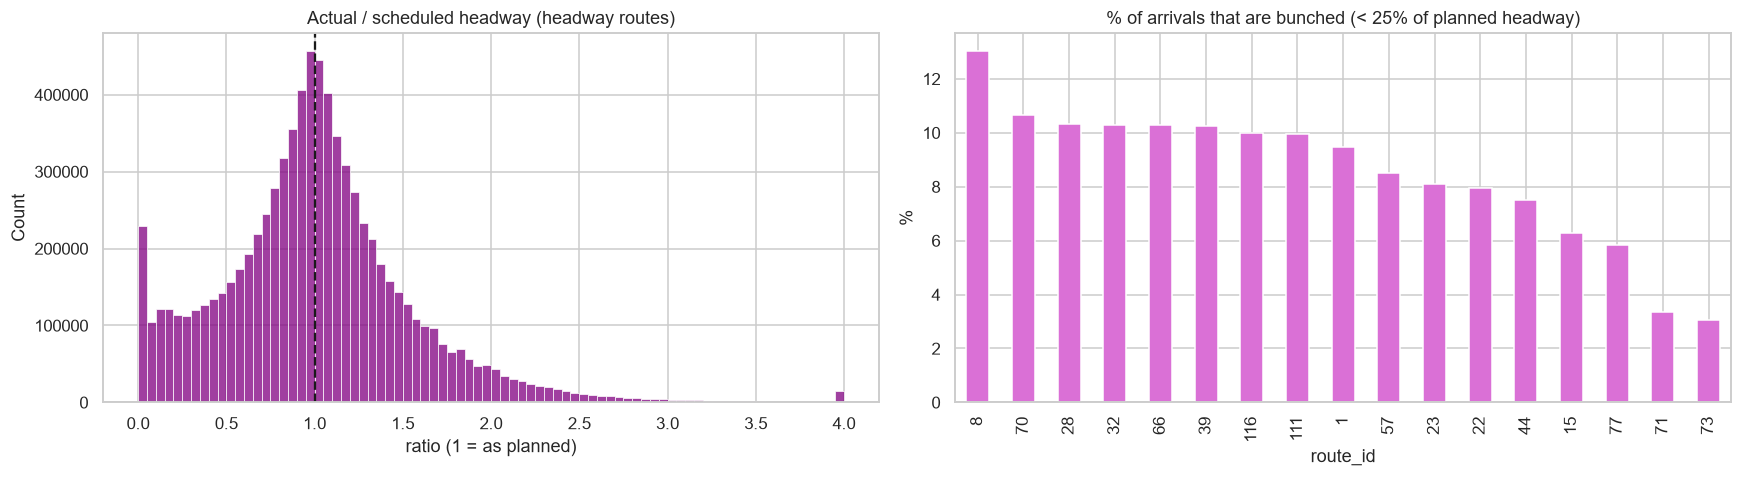

,% of headway events
state,
normal,68.9
gap (1.5â€“2Ã—),10.0
bunched (<25%),8.7
close,7.9
big gap (>2Ã—),4.5


In [16]:
hw = df[(df.standard_type=='Headway') & df.headway.notna() & (df.scheduled_headway>0)].copy()
hw['ratio'] = hw.headway / hw.scheduled_headway
hw['state'] = pd.cut(hw.ratio, [0, .25, .5, 1.5, 2, np.inf], labels=['bunched (<25%)','close','normal','gap (1.5â€“2Ã—)','big gap (>2Ã—)'])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(hw.ratio.clip(0, 4), bins=80, ax=axes[0], color='purple')
axes[0].axvline(1, color='k', ls='--'); axes[0].set(title='Actual / scheduled headway (headway routes)', xlabel='ratio (1 = as planned)')
(hw.groupby('route_id', observed=True).ratio.apply(lambda x: (x<.25).mean()*100).sort_values(ascending=False)
   .plot.bar(ax=axes[1], color='orchid'))
axes[1].set(title='% of arrivals that are bunched (< 25% of planned headway)', ylabel='%')
save('bunching')
hw.state.value_counts(normalize=True).mul(100).round(1).to_frame('% of headway events')

## 7. Relationships between candidate features and the target

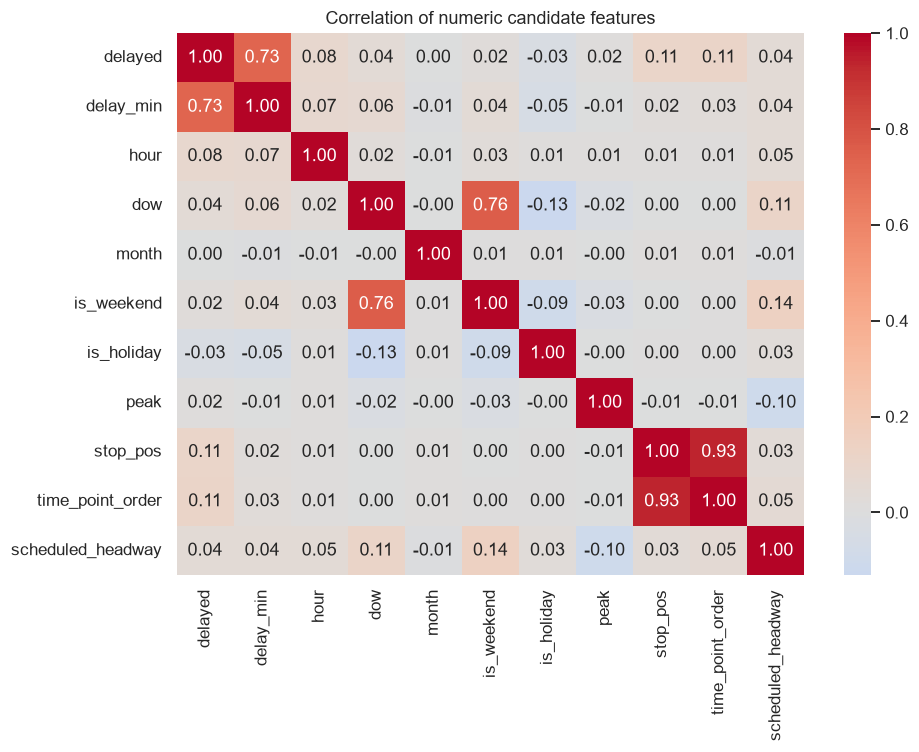

In [17]:
df['peak'] = df.hour.isin([7,8,16,17,18]).astype('int8')
cand = df[['delayed','delay_min','hour','dow','month','is_weekend','is_holiday','peak','stop_pos','time_point_order','scheduled_headway']]
plt.figure(figsize=(9,7))
sns.heatmap(cand.sample(500000, random_state=0).corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric candidate features'); save('correlation')

Linear correlations are weak (as expected for categorical/cyclical drivers like route, stop and hour),
which is exactly why **tree ensembles** (random forest, XGBoost) are expected to beat logistic regression,
and why we will add **target-encoded historical delay rates** per route/stop/hour.

## 8. Key findings â†’ implications

| Finding | Implication for next steps |
|---|---|
| ~29 % of events delayed (minority class) | Use class weights, threshold tuning, PR-AUC/F1, not accuracy |
| Strong hour-of-day effect (afternoon/PM peak worst); weekends worse in afternoons; holidays much better | Features: `hour` (cyclical sin/cos), `peak` flags, `is_weekend`, `is_holiday`, hour Ã— weekend interaction |
| Seasonality tied to school calendar | `is_school_day` feature (Boston Public Schools / university terms), `month` |
| Large differences between routes, directions and stops (route 44, 28, 39 worst; 111, 66 best) | Categorical route/stop/direction + historical delay rates (computed on train only) |
| Delay peaks mid-route and recovers at the terminal (schedule padding) | `stop_pos`, `time_point_order`, `point_type` (non-linear â†’ trees) |
| Spiky bad days | Join hourly weather (snow, rain, temperature) and event calendar |
| Start delay â‡’ end delay; bunching on frequent routes | Lagged previous-trip delay; propagation & bunching extension |
| Cancelled/unobserved events vary by route | Report missing-trip rate on dashboard as separate reliability KPI |
| Mild month-to-month drift | **Time-based split** (Janâ€“Sep train, Oct validation, Novâ€“Dec test) |